# Prior-loading scaling laws

Standalone comparison of late-context prior loading across Llama/Gemma/Qwen and final Pythia checkpoints. The configuration can switch the horizontal scaling variable and the definition of absolute prior loading without rerunning model inference.

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit

# Locate direction_of_ignorance whether the kernel starts in the repository root,
# direction_of_ignorance, or notebook_plotters.
cwd = Path.cwd().resolve()
root_candidates = (cwd, cwd / "direction_of_ignorance", cwd.parent)
ROOT = next(
    (path for path in root_candidates if (path / "notebook_plotters").exists() and (path / "data").exists()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Could not locate the direction_of_ignorance directory.")

DATA_DIR = ROOT / "data"
EXPORT_DIR = ROOT / "notebook_plotters" / "plot_export"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
#######################################################
# Plot controls
#######################################################
x_axis = "latent_dimension"  # "latent_dimension" or "model_size"
# x_axis = "model_size"
# absolute_mean_lambda: abs of the signed mean across tokens and trajectories.
# mean_absolute_lambda: per trajectory mean(abs(token lambda)), then mean across trajectories.
# generation_entropy: per-trajectory mean next-token entropy over loading_interval.
y_axis = "absolute_mean_lambda"
# y_axis = "mean_absolute_lambda"
# y_axis = "generation_entropy"
loading_interval = (250, 300)  # half-open [start, stop) token positions
vocab_coverage = 0.7
sigma_mult = 1.5
fit_family_scaling = False  # fit each model family separately to y = c * x**alpha


reference_slope = -2.0


wikitext_num_passages = 200
pythia_num_passages = 300
num_tokens = 300

family1_models = [
    "meta-llama/Llama-3.2-1B",
    "meta-llama/Llama-3.2-3B",
    "meta-llama/Llama-3.1-8B",
    "meta-llama/Llama-3.1-70B",
    "meta-llama/Llama-3.1-405B",
]
family2_models = [
    "google/gemma-3-1b-pt",
    "google/gemma-3-4b-pt",
]
family3_models = [
    "Qwen/Qwen2.5-1.5B",
    "Qwen/Qwen2.5-3B",
]
family_model_groups = {
    "Llama": family1_models,
    "Gemma": family2_models,
    "Qwen": family3_models,
}
family_models = [
    model_name
    for model_names in family_model_groups.values()
    for model_name in model_names
]

pythia_models = [
    # "EleutherAI/pythia-70m",
    # "EleutherAI/pythia-160m",
    # "EleutherAI/pythia-410M",
    # "EleutherAI/pythia-1B",
    # "EleutherAI/pythia-1.4B",
    # "EleutherAI/pythia-2.8b",
    # "EleutherAI/pythia-6.9b",
]

# Nominal parameter counts and residual-stream dimensionalities.
model_metadata = {
    "meta-llama/Llama-3.2-1B": {"model_size": 1.0e9, "latent_dimension": 2_048},
    "meta-llama/Llama-3.2-3B": {"model_size": 3.0e9, "latent_dimension": 3_072},
    "meta-llama/Llama-3.1-8B": {"model_size": 8.0e9, "latent_dimension": 4_096},
    "meta-llama/Llama-3.1-70B": {"model_size": 70.0e9, "latent_dimension": 8_192},
    "meta-llama/Llama-3.1-405B": {"model_size": 405.0e9, "latent_dimension": 16_384},
    "google/gemma-3-1b-pt": {"model_size": 1.0e9, "latent_dimension": 1_152},
    "google/gemma-3-4b-pt": {"model_size": 4.0e9, "latent_dimension": 2_560},
    "Qwen/Qwen2.5-1.5B": {"model_size": 1.5e9, "latent_dimension": 1_536},
    "Qwen/Qwen2.5-3B": {"model_size": 3.0e9, "latent_dimension": 2_048},
    "EleutherAI/pythia-410M": {"model_size": 0.41e9, "latent_dimension": 1_024},
    "EleutherAI/pythia-1B": {"model_size": 1.0e9, "latent_dimension": 2_048},
    "EleutherAI/pythia-1.4B": {"model_size": 1.4e9, "latent_dimension": 2_048},
    "EleutherAI/pythia-2.8b": {"model_size": 2.8e9, "latent_dimension": 2_560},
    "EleutherAI/pythia-6.9b": {"model_size": 6.9e9, "latent_dimension": 4_096},
}

if x_axis not in {"latent_dimension", "model_size"}:
    raise ValueError("x_axis must be 'latent_dimension' or 'model_size'.")
if y_axis not in {
    "absolute_mean_lambda",
    "mean_absolute_lambda",
    "generation_entropy",
}:
    raise ValueError(
        "y_axis must be 'absolute_mean_lambda', 'mean_absolute_lambda', "
        "or 'generation_entropy'."
    )

interval_start, interval_stop = loading_interval
if not 0 <= interval_start < interval_stop <= num_tokens:
    raise ValueError(
        f"loading_interval must satisfy 0 <= start < stop <= {num_tokens}."
    )
missing_metadata = set(family_models + pythia_models) - set(model_metadata)
if missing_metadata:
    raise KeyError(f"Missing model metadata for: {sorted(missing_metadata)}")

### Figure 5 — scaling with six math/reasoning-specialized checkpoints

Gemma 4B GRPO* is exploratory: GRPO is author-claimed with unverified training provenance. Its direct parent is Instruct. Both checkpoints were refit from saved raw states using the exact recovered original 70% scaling reference; see results.md for the paired comparison. This sixth checkpoint is in addition to the five described below.

Original pretrained scaling points plus five math/reasoning-specialized models in red. Gemma 1B SFT+GRPO: mean λ=0.439780, below matched FP32 pretrained (0.824613), but above its immediate Instruct parent (0.434189). Thus the additional adapter increases λ by 1.29%; the overall pretrained-to-specialized decrease includes instruction tuning. SimpleRL-Llama 8B, Qwen-Math 1.5B, DeepHermes 3B and R1-Llama 70B remain unchanged. Qwen-Math is math specialization, not R1 distillation. Original base plot points retain their original numerical precision; matched FP32 controls are documented separately in results.md. Matched BOS; 70% coverage; 200 WikiText passages; positions 250–299; whiskers ±1 delta-method log-SE, not 95% intervals. Optional arrows indicate comparisons rather than direct parentage; R1-Llama 70B derives from Llama 3.3 Instruct, not directly from 3.1 Base. Ordinate: absolute signed mean loading.


## Appendix: master scaling plot
All completed 70%-coverage reasoning/math variants are shown, with base models in blue and instruction controls in orange. Red labels are horizontal, 7 pt. Mistral/Phi earlier 60%-coverage experiments are not pooled here. Values are |mean λ|; signed values are retained in the export. Mixed-precision and cross-version comparisons remain descriptive.

/tmp/ipykernel_2620992/2079608905.py:205: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  ax5.plot(gx, 3*(gx/guide_anchor)**-2, 'k--', lw=2.2, alpha=0.3, zorder=1, color = fig5_blue)


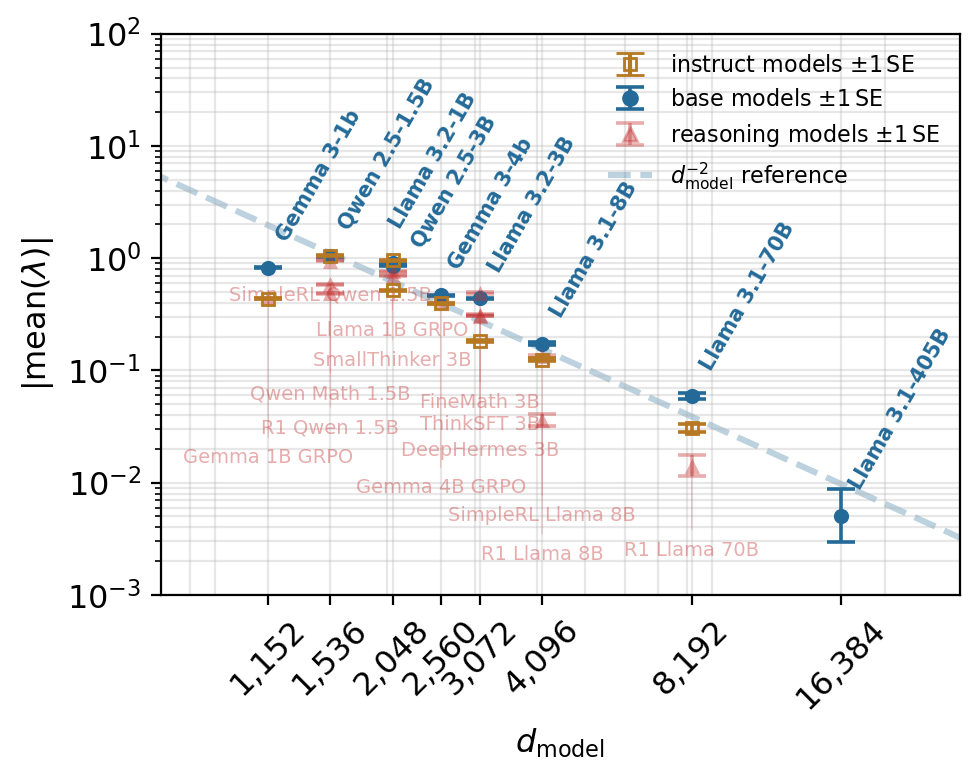

In [3]:
# Appendix master scaling plot: original scaling panel, specialized checkpoints, and instruction controls.
# Standalone cell; does not run inference or the random-direction null cells.
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
root = next((p for p in (cwd, cwd.parent, cwd / 'direction_of_ignorance')
             if (p / 'prior_calibration/data').is_dir()), None)
if root is None:
    raise FileNotFoundError('Run from direction_of_ignorance or notebook_plotters.')
export = root / 'notebook_plotters/plot_export'
export.mkdir(exist_ok=True)
summary = json.loads((root / 'prior_calibration/data/scaling_reasoning_pairs_matched_cov70.json').read_text())
assert summary['coverage'] == .7 and summary['window'] == [250, 300]
matched = {p['key']: p for p in summary['models']}
# Replace only the 8B reasoning point with the validated direct-RL control.
rl_run = root / 'prior_calibration/scaling_simplerl_cov07_v1'
rl_key = 'llama8_simplerl'
rl_manifest = json.loads((rl_run / 'manifest.json').read_text())
assert json.loads((rl_run / rl_key / 'identity_gate.json').read_text())['passed']
assert json.loads((rl_run / rl_key / 'complete.json').read_text())['n'] == 200
rl_values = []
for i in range(200):
    with np.load(rl_run / rl_key / 'results' / f'{i:04}.npz') as z:
        assert np.array_equal(z['token_ids'], rl_manifest['models'][rl_key]['token_ids'][i])
        assert str(z['text_sha256']) == rl_manifest['passages'][i]['sha256']
        rl_values.append(float(z['lambda_values'][250:300].mean()))
matched[rl_key] = dict(hidden_dimension=4096, passage_means=rl_values)

gemma_run = root / 'prior_calibration/scaling_gemma1_reasoning_cov07_v1'
assert json.loads((gemma_run / 'conversion_gate.json').read_text())['passed']
for gemma_key in ('gemma1_reasoning', 'gemma1_instruct', 'gemma1_base'):
    assert json.loads((gemma_run / gemma_key / 'complete.json').read_text())['n'] == 200
    assert json.loads((gemma_run / gemma_key / 'identity_gate.json').read_text())['passed']
    gemma_values = [float(np.load(gemma_run / gemma_key / 'results' / f'{i:04}.npz')['lambda_values'][250:300].mean()) for i in range(200)]
    matched[gemma_key] = dict(hidden_dimension=1152, passage_means=gemma_values)

# Original pretrained models, ordering, family gradients and plot dimensions.
gemma4_refit = json.loads((root / 'prior_calibration/data/gemma4_scaling_refit_cov70.json').read_text())
assert gemma4_refit['original_fit_reproduced'] and gemma4_refit['coverage'] == .7
matched['gemma4_reasoning'] = next(p for p in gemma4_refit['models'] if p['key'] == 'reasoning')
# Validated instruction controls (2026-09-23).
def load_control_run(run_name, keys):
    run = root / 'prior_calibration' / run_name
    manifest = json.loads((run / 'manifest.json').read_text())
    for key in keys:
        dest = run / key
        assert json.loads((dest / 'complete.json').read_text())['n'] == 200
        assert json.loads((dest / 'identity_gate.json').read_text())['passed']
        assert json.loads((dest / 'reference_gate.json').read_text())['passed']
        spec = manifest['models'][key]
        values = []
        for i, passage in enumerate(manifest['passages']):
            with np.load(dest / 'results' / f'{i:04}.npz') as z:
                assert str(z['text_sha256']) == passage['sha256']
                assert np.array_equal(z['token_ids'], spec['token_ids'][i])
                assert z['lambda_values'].shape == (300,)
                assert np.isfinite(z['lambda_values']).all()
                values.append(float(z['lambda_values'][250:300].mean()))
        runtime = json.loads((dest / 'runtime.json').read_text())
        matched[key] = dict(hidden_dimension=spec['config']['hidden_size'],
                            passage_means=values, dtype=runtime['dtype'],
                            model_id=spec['model_id'], revision=spec['revision'])

load_control_run('scaling_instruct_controls_cov07_v1',
                 ['llama1_instruct', 'llama3_instruct', 'llama8_instruct',
                  'qwen1p5_instruct', 'qwen3_instruct'])
load_control_run('scaling_remaining_pairs_cov07_v1', ['llama1_grpo', 'qwen3_smallthinker'])
matched['gemma4_instruct'] = next(p for p in gemma4_refit['models'] if p['key'] == 'instruct')


load_control_run('scaling_llama3_additions_cov07_v1', ['llama3_finemath', 'llama3_thinksft'])
# SimpleRL uses an older manifest without reference_gate.json; validate its
# retained passage outputs and identity gate directly.
simple = root / 'prior_calibration/scaling_simplerl_cov07_v1'
assert json.loads((simple/'qwen1p5_simplerl/complete.json').read_text())['n'] == 200
assert json.loads((simple/'qwen1p5_simplerl/identity_gate.json').read_text())['passed']
matched['qwen1p5_simplerl'] = dict(hidden_dimension=1536, passage_means=[
 float(np.load(simple/'qwen1p5_simplerl/results'/f'{i:04}.npz')['lambda_values'][250:300].mean()) for i in range(200)])
families = {
    'Llama': [('meta-llama/Llama-3.2-1B', 2048), ('meta-llama/Llama-3.2-3B', 3072),
              ('meta-llama/Llama-3.1-8B', 4096), ('meta-llama/Llama-3.1-70B', 8192),
              ('meta-llama/Llama-3.1-405B', 16384)],
    'Gemma': [('google/gemma-3-1b-pt', 1152), ('google/gemma-3-4b-pt', 2560)],
    'Qwen': [('Qwen/Qwen2.5-1.5B', 1536), ('Qwen/Qwen2.5-3B', 2048)],
}
cmaps = {'Llama': plt.cm.Blues, 'Gemma': plt.cm.Purples, 'Qwen': plt.cm.Oranges}
fig5_size = (5, 4)
fig5_font = 11.5
fig5_label_font = 7.5
fig5_sigma = 1.0
fig5_red = '#c43131'
alpha_red = 0.4  # Shared opacity for reasoning markers, whiskers, labels, arrows and legend
fig5_blue = '#246a98'
curvy_arrow = False  # Show semicircle comparison arrows for reasoning models
fig5, ax5 = plt.subplots(figsize=fig5_size, dpi=200)
ms = 30
rows = []
base_means = {}

def fig5_point(x, values, label, color, offset, reasoning=False):
    values = np.asarray(values, dtype=float)
    assert values.shape == (200,) and np.isfinite(values).all()
    signed = float(values.mean()); mean = abs(signed)
    se = float(values.std(ddof=1) / np.sqrt(len(values)))
    # Delta-method SE of log(abs(mean)); preserve the arithmetic-mean estimand.
    assert mean > 0
    log_se = se / mean
    lower, upper = mean * np.exp(np.array([-1, 1]) * fig5_sigma * log_se)
    yerr = np.array([[mean - lower], [upper - mean]])
    ax5.errorbar(x, mean, yerr=yerr, fmt='none', ecolor=color,
                elinewidth=1.3, capsize=5, capthick=1.3, alpha=alpha_red if reasoning else 1, zorder=3)
    ax5.scatter(x, mean, s=ms, marker='^' if reasoning else 'o', facecolors=color, edgecolors=color,
                linewidths=0, alpha=alpha_red if reasoning else 1, zorder=4)
    ax5.annotate(label, (x, mean), xytext=offset, textcoords='offset points',
                 fontsize=7 if reasoning else fig5_label_font, fontweight='normal' if reasoning else 'bold', color=color, alpha=alpha_red if reasoning else 1,
                 rotation=0 if reasoning else 60, rotation_mode='default' if reasoning else 'anchor',
                 ha='center' if reasoning else 'left', va='top' if reasoning else 'bottom')
    rows.append(dict(label=label, hidden_dimension=x, signed_mean=signed,
                     absolute_mean=mean, se=se, log_se=log_se, whisker_lower=float(lower),
                     whisker_upper=float(upper), reasoning=reasoning))
    return mean

for family, models in families.items():
    for model, x in models:
        color = fig5_blue
        tag = model.replace('/', '__'); cache = root / 'data/fig2_cache'
        with np.load(cache / f'panelA_{tag}_N200_T300.npz') as fit:
            assert bool(fit['BOS_token']) and np.isclose(fit['vocab_coverage'], .7)
            direction = fit['d_hat'].astype(float); beta = float(fit['beta_star'])
        hidden = np.load(cache / f'panelA_y_{tag}_N200_T300_coherent.npy', mmap_mode='r')
        values = [(np.asarray(y[250:300], float) @ direction / beta).mean() for y in hidden]
        label = model.split('/')[-1].replace('Llama-', 'Llama ').replace('gemma-', 'Gemma ').replace('Qwen', 'Qwen ').replace('-pt', '')
        offset = (12, 4) if model == 'Qwen/Qwen2.5-3B' else ((4, 12) if model.endswith('Llama-3.2-1B') else (8, 8))
        base_means[model] = fig5_point(x, values, label, color, offset)

from matplotlib.path import Path as MplPath
from matplotlib.transforms import Affine2D

def fig5_semicircle(posA, posB, **kwargs):
    # Work in display coordinates: log axes must not distort the circle.
    xa, ya = posA; xb, yb = posB
    shift_pixels = 3 * fig5.dpi / 72  
    xa -= shift_pixels; xb -= shift_pixels
    assert np.isclose(xa, xb) and ya > yb
    radius = (ya - yb) / 2 + 10
    # Right half-circle, reflected vertically to run top -> bottom.
    # The endpoint tangent is exactly horizontal and points left.
    arc = MplPath.arc(-80, 80, n=8)
    return Affine2D().scale(radius, -radius).translate(xa, (ya + yb)/2).transform_path(arc)

def fig5_exact_tip(path, mutation_size, linewidth, aspect_ratio=1):
    # Keep the head's tip exactly at the unshortened semicircle endpoint.
    tip = path.vertices[-1]
    length, halfwidth = .4 * mutation_size, .2 * mutation_size
    vertices = [tip, tip + [length, halfwidth], tip + [length, -halfwidth], tip]
    head = MplPath(vertices, [MplPath.MOVETO, MplPath.LINETO, MplPath.LINETO, MplPath.CLOSEPOLY])
    head = Affine2D().rotate_deg_around(tip[0], tip[1], 20).transform_path(head)
    return [path, head], [False, True]

reasoning_models = [('llama1_grpo', 'Llama 1B GRPO', 'meta-llama/Llama-3.2-1B'), ('llama3b_reasoning', 'DeepHermes 3B', 'meta-llama/Llama-3.2-3B'), ('llama3_finemath', 'FineMath 3B', 'meta-llama/Llama-3.2-3B'), ('llama3_thinksft', 'ThinkSFT 3B', 'meta-llama/Llama-3.2-3B'), ('llama8_simplerl', 'SimpleRL Llama 8B', 'meta-llama/Llama-3.1-8B'), ('llama8_reasoning', 'R1 Llama 8B', 'meta-llama/Llama-3.1-8B'), ('llama70_reasoning', 'R1 Llama 70B', 'meta-llama/Llama-3.1-70B'), ('gemma1_reasoning', 'Gemma 1B GRPO', 'google/gemma-3-1b-pt'), ('gemma4_reasoning', 'Gemma 4B GRPO', 'google/gemma-3-4b-pt'), ('qwen1p5_math', 'Qwen Math 1.5B', 'Qwen/Qwen2.5-1.5B'), ('qwen1p5_reasoning', 'R1 Qwen 1.5B', 'Qwen/Qwen2.5-1.5B'), ('qwen1p5_simplerl', 'SimpleRL Qwen 1.5B', 'Qwen/Qwen2.5-1.5B'), ('qwen3_smallthinker', 'SmallThinker 3B', 'Qwen/Qwen2.5-3B')]
for key, label, base in reasoning_models:
    p = matched[key]; x = p['hidden_dimension']
    # offset = (0, -2)
    offset = (0, -9)
    mean = fig5_point(x, p['passage_means'], label, fig5_red, offset, reasoning=True)
    # Arrows show comparisons; the 70B comparison is NOT direct parentage.
    if curvy_arrow:
        ax5.annotate('', xy=(x * 1.12, mean), xytext=(x * 1.12, base_means[base]),
                     arrowprops=dict(arrowstyle=fig5_exact_tip, color=fig5_red, lw=1.6, alpha=alpha_red,
                                     connectionstyle=fig5_semicircle,
                                     shrinkA=0, shrinkB=0,
                                     linestyle='-'), zorder=2)

# Instruction controls use hollow orange squares, distinct from reasoning.
instruction_controls = [
 ('llama1_instruct', 'Llama 3.2 1B Instruct'),
 ('llama3_instruct', 'Llama 3.2 3B Instruct'),
 ('llama8_instruct', 'Llama 3.1 8B Instruct'),
 ('qwen1p5_instruct', 'Qwen 2.5 1.5B Instruct'),
 ('qwen3_instruct', 'Qwen 2.5 3B Instruct'),
 ('gemma1_instruct', 'Gemma 3 1B IT'),
 ('gemma4_instruct', 'Gemma 3 4B IT'),
 ('llama70_instruct', 'Llama 3.3 70B Instruct (cross-version)'),
]
for key, label in instruction_controls:
    p = matched[key]; values = np.asarray(p['passage_means'], float)
    assert values.shape == (200,) and np.isfinite(values).all()
    signed = float(values.mean()); mean = abs(signed)
    se = float(values.std(ddof=1)/np.sqrt(200)); log_se = se/mean
    lo, hi = mean*np.exp(np.array([-1,1])*fig5_sigma*log_se)
    ax5.errorbar(p['hidden_dimension'], mean, yerr=[[mean-lo],[hi-mean]],
                 fmt='s', mfc='none', mec='#b67820', color='#b67820',
                 markersize=4, elinewidth=1.3, capsize=5, capthick=1.3, zorder=5)
    rows.append(dict(label=label, key=key, hidden_dimension=p['hidden_dimension'],
                     signed_mean=signed, absolute_mean=mean, se=se, log_se=log_se,
                     whisker_lower=float(lo), whisker_upper=float(hi),
                     reasoning=False, stage='instruct', dtype=p.get('dtype', 'see source runtime')))

xs = sorted({x for models in families.values() for _, x in models})
padding = (xs[-1]/xs[0])**.08; guide_anchor = xs[0]/padding
gx = np.geomspace(500, 300000, 600)
ax5.plot(gx, 3*(gx/guide_anchor)**-2, 'k--', lw=2.2, alpha=0.3, zorder=1, color = fig5_blue)
ax5.set(xscale='log', yscale='log', xlim=(700, xs[-1]*padding*1.4), ylim=(.001, 100))
ax5.set_xticks(xs, [f'{x:,}' for x in xs], rotation=45)
ax5.tick_params(axis='x', which='minor', bottom=False, labelbottom=False)
ax5.tick_params(labelsize=fig5_font)
ax5.set_xlabel(r'$d_\text{model}$', fontsize=fig5_font)
ax5.set_ylabel(r'$|\mathrm{mean}(\lambda)|$', fontsize=fig5_font)
ax5.grid(True, which='both', alpha=.3)
from matplotlib.lines import Line2D
from matplotlib.container import ErrorbarContainer
from matplotlib.legend_handler import HandlerErrorbar
ax5.legend(handles=[
    ax5.errorbar([np.nan], [np.nan], yerr=[1.0], fmt='s', mfc='none', color='#b67820', markersize=4, capsize=5, label=r'instruct models $\pm 1\,\mathrm{SE}$'),
    ax5.errorbar([np.nan], [np.nan], yerr=[1.0], fmt='o', color=fig5_blue, markersize=5, elinewidth=1.3, capsize=5, capthick=1.3, label=r'base models $\pm 1\,\mathrm{SE}$'),
    ax5.errorbar([np.nan], [np.nan], yerr=[1.0], fmt='^', color=fig5_red, markersize=5, elinewidth=1.3, capsize=5, capthick=1.3, alpha=alpha_red, label=r'reasoning models $\pm 1\,\mathrm{SE}$'),
    Line2D([], [], color=fig5_blue, linestyle='--', linewidth=2.2, alpha=.3, label=r'$d_\text{model}^{-2}$ reference'),
], loc='upper right', frameon=False, fontsize=8,
           handler_map={ErrorbarContainer: HandlerErrorbar(yerr_size=0.5)})
fig5.tight_layout()

fig5.canvas.draw()
renderer=fig5.canvas.get_renderer()
occupied=[]
red_labels=[t for t in ax5.texts if t.get_color()==fig5_red]
for text in sorted(red_labels,key=lambda t: -ax5.transData.transform(t.xy)[1]):
    shift=-9
    for attempt in range(70):
        text.set_position((0,shift))
        box=text.get_window_extent(renderer).expanded(1.04,1.10)
        if not any(box.overlaps(other) for other in occupied):break
        shift-=9
    occupied.append(box)
    if shift < -9:
        ax5.annotate('',xy=text.xy,xytext=(0,shift+2),textcoords='offset points',
                     arrowprops=dict(arrowstyle='-',color=fig5_red,alpha=.2,lw=.5))

for ext in ('png', 'pdf'):
    fig5.savefig(export / f'scaling_master_all_variants.{ext}', bbox_inches='tight', dpi=200)
(export / 'scaling_master_all_variants.json').write_text(json.dumps(
    dict(coverage=.7, window=[250,300], n=200, whiskers='exp(log(abs(mean)) +/- 1 delta-method log SE); not 95% CI', models=rows,
         caveat='Gemma 4B GRPO is exploratory author-claimed GRPO; immediate parent Instruct. Exact original 70% frequency reference recovered. 70B connector is cross-version, not direct parentage; signed means retained. New instruction controls use native BF16; Gemma controls use FP32. This mixed-precision overview is not a precision-matched causal test. Llama-3.1-70B-Instruct and expanded reasoning candidate campaign remain unlaunched.'), indent=2))
plt.show()


### Main scaling figure: minimum among evaluated variants
For each base, the red point is the reasoning/math checkpoint with the lowest observed mean λ among the variants evaluated. This is an outcome-selected descriptive summary, not a representative effect across variants. The preceding appendix master retains every evaluated variant, including increases. Whiskers are ±1 SE for each selected mean and do not account for variant selection.

Eligibility restriction: Llama 1B GRPO is excluded from the main plot. Llama 8B and Qwen 1.5B exclude R1-based variants; their selected counterparts are SimpleRL and Qwen-Math, respectively. Other groups retain their existing eligibility. All red labels use the same lower-right point offset and 60-degree rotation.

/tmp/ipykernel_2620992/1685864696.py:213: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  ax5.plot(gx, base_fit_c * gx**base_slope, 'k--', lw=2.2, alpha=0.3, zorder=1, color=fig5_blue)


fig saved under /home/jl3499/LLM_dark_matter/direction_of_ignorance/iclr2027/figures/fig5_scaling_reasoning


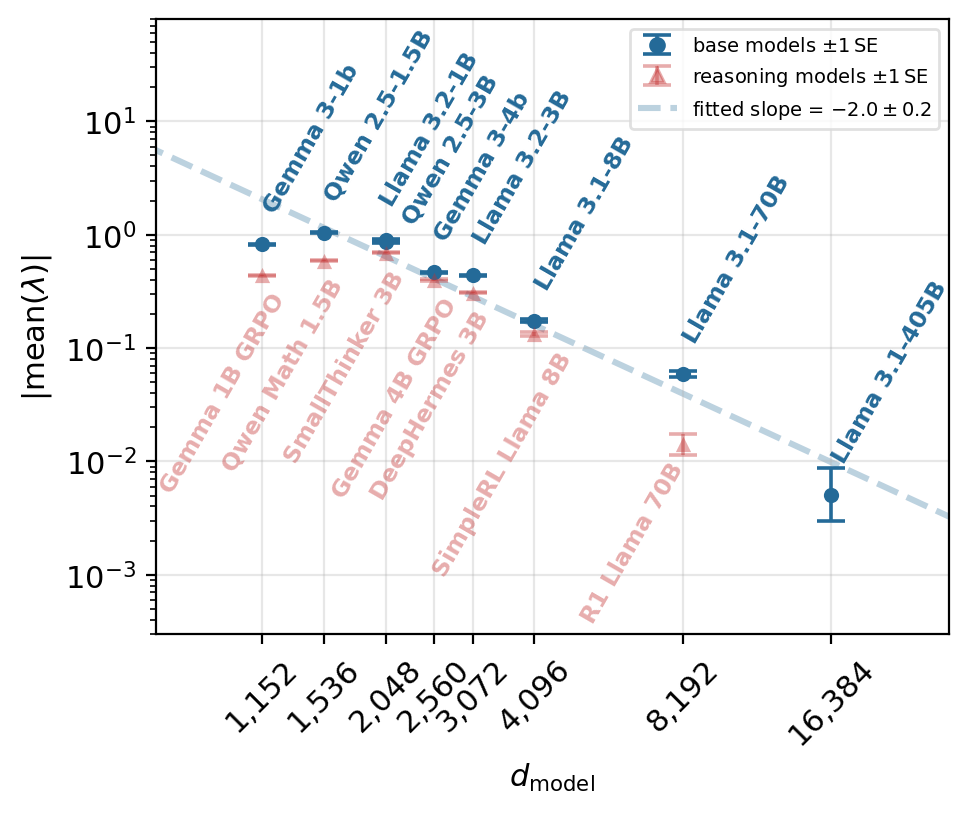

In [4]:
# Figure 5: original scaling panel, lowest measured mean-lambda specialized counterpart per base; no instruction controls.
# Standalone cell; does not run inference or the random-direction null cells.
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
root = next((p for p in (cwd, cwd.parent, cwd / 'direction_of_ignorance')
             if (p / 'prior_calibration/data').is_dir()), None)
if root is None:
    raise FileNotFoundError('Run from direction_of_ignorance or notebook_plotters.')
export = root / 'notebook_plotters/plot_export'
export.mkdir(exist_ok=True)
figures_dir = export
summary = json.loads((root / 'prior_calibration/data/scaling_reasoning_pairs_matched_cov70.json').read_text())
assert summary['coverage'] == .7 and summary['window'] == [250, 300]
matched = {p['key']: p for p in summary['models']}
# Replace only the 8B reasoning point with the validated direct-RL control.
rl_run = root / 'prior_calibration/scaling_simplerl_cov07_v1'
rl_key = 'llama8_simplerl'
rl_manifest = json.loads((rl_run / 'manifest.json').read_text())
assert json.loads((rl_run / rl_key / 'identity_gate.json').read_text())['passed']
assert json.loads((rl_run / rl_key / 'complete.json').read_text())['n'] == 200
rl_values = []
for i in range(200):
    with np.load(rl_run / rl_key / 'results' / f'{i:04}.npz') as z:
        assert np.array_equal(z['token_ids'], rl_manifest['models'][rl_key]['token_ids'][i])
        assert str(z['text_sha256']) == rl_manifest['passages'][i]['sha256']
        rl_values.append(float(z['lambda_values'][250:300].mean()))
matched[rl_key] = dict(hidden_dimension=4096, passage_means=rl_values)

gemma_run = root / 'prior_calibration/scaling_gemma1_reasoning_cov07_v1'
assert json.loads((gemma_run / 'conversion_gate.json').read_text())['passed']
for gemma_key in ('gemma1_reasoning', 'gemma1_instruct', 'gemma1_base'):
    assert json.loads((gemma_run / gemma_key / 'complete.json').read_text())['n'] == 200
    assert json.loads((gemma_run / gemma_key / 'identity_gate.json').read_text())['passed']
    gemma_values = [float(np.load(gemma_run / gemma_key / 'results' / f'{i:04}.npz')['lambda_values'][250:300].mean()) for i in range(200)]
    matched[gemma_key] = dict(hidden_dimension=1152, passage_means=gemma_values)

# Original pretrained models, ordering, family gradients and plot dimensions.
gemma4_refit = json.loads((root / 'prior_calibration/data/gemma4_scaling_refit_cov70.json').read_text())
assert gemma4_refit['original_fit_reproduced'] and gemma4_refit['coverage'] == .7
matched['gemma4_reasoning'] = next(p for p in gemma4_refit['models'] if p['key'] == 'reasoning')
# Validated instruction controls (2026-09-23).
def load_control_run(run_name, keys):
    run = root / 'prior_calibration' / run_name
    manifest = json.loads((run / 'manifest.json').read_text())
    for key in keys:
        dest = run / key
        assert json.loads((dest / 'complete.json').read_text())['n'] == 200
        assert json.loads((dest / 'identity_gate.json').read_text())['passed']
        assert json.loads((dest / 'reference_gate.json').read_text())['passed']
        spec = manifest['models'][key]
        values = []
        for i, passage in enumerate(manifest['passages']):
            with np.load(dest / 'results' / f'{i:04}.npz') as z:
                assert str(z['text_sha256']) == passage['sha256']
                assert np.array_equal(z['token_ids'], spec['token_ids'][i])
                assert z['lambda_values'].shape == (300,)
                assert np.isfinite(z['lambda_values']).all()
                values.append(float(z['lambda_values'][250:300].mean()))
        runtime = json.loads((dest / 'runtime.json').read_text())
        matched[key] = dict(hidden_dimension=spec['config']['hidden_size'],
                            passage_means=values, dtype=runtime['dtype'],
                            model_id=spec['model_id'], revision=spec['revision'])

load_control_run('scaling_instruct_controls_cov07_v1',
                 ['llama1_instruct', 'llama3_instruct', 'llama8_instruct',
                  'qwen1p5_instruct', 'qwen3_instruct'])
load_control_run('scaling_remaining_pairs_cov07_v1', ['qwen3_smallthinker'])
matched['gemma4_instruct'] = next(p for p in gemma4_refit['models'] if p['key'] == 'instruct')

load_control_run('scaling_llama3_additions_cov07_v1', ['llama3_finemath', 'llama3_thinksft'])
# SimpleRL uses an older manifest without reference_gate.json; validate its
# retained passage outputs and identity gate directly.
simple = root / 'prior_calibration/scaling_simplerl_cov07_v1'
assert json.loads((simple/'qwen1p5_simplerl/complete.json').read_text())['n'] == 200
assert json.loads((simple/'qwen1p5_simplerl/identity_gate.json').read_text())['passed']
matched['qwen1p5_simplerl'] = dict(hidden_dimension=1536, passage_means=[
 float(np.load(simple/'qwen1p5_simplerl/results'/f'{i:04}.npz')['lambda_values'][250:300].mean()) for i in range(200)])

families = {
    'Llama': [('meta-llama/Llama-3.2-1B', 2048), ('meta-llama/Llama-3.2-3B', 3072),
              ('meta-llama/Llama-3.1-8B', 4096), ('meta-llama/Llama-3.1-70B', 8192),
              ('meta-llama/Llama-3.1-405B', 16384)],
    'Gemma': [('google/gemma-3-1b-pt', 1152), ('google/gemma-3-4b-pt', 2560)],
    'Qwen': [('Qwen/Qwen2.5-1.5B', 1536), ('Qwen/Qwen2.5-3B', 2048)],
}
cmaps = {'Llama': plt.cm.Blues, 'Gemma': plt.cm.Purples, 'Qwen': plt.cm.Oranges}
fig5_size = (5, 4.2)
fig5_font = 11
fig5_label_font = 8.5
fig5_legend_font = 7
# Same font setup as fig4_2_alpha_sweep.ipynb (DejaVu Sans, TrueType embedding).
# Shared with the appendix random-direction null cell so both figures match.
fig5_rc = {
    'font.family': 'DejaVu Sans', 'font.size': fig5_font,
    'xtick.labelsize': fig5_font, 'ytick.labelsize': fig5_font,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
}
plt.rcParams.update(fig5_rc)
fig5_sigma = 1.0
fig5_red = '#c43131'
alpha_red = 0.4  # Shared opacity for reasoning markers, whiskers, labels, arrows and legend
fig5_blue = '#246a98'
curvy_arrow = False  # Show semicircle comparison arrows for reasoning models
fig5, ax5 = plt.subplots(figsize=fig5_size, dpi=200)
ms = 30
rows = []
base_means = {}

def fig5_point(x, values, label, color, offset, reasoning=False):
    values = np.asarray(values, dtype=float)
    assert values.shape == (200,) and np.isfinite(values).all()
    signed = float(values.mean()); mean = abs(signed)
    se = float(values.std(ddof=1) / np.sqrt(len(values)))
    # Delta-method SE of log(abs(mean)); preserve the arithmetic-mean estimand.
    assert mean > 0
    log_se = se / mean
    lower, upper = mean * np.exp(np.array([-1, 1]) * fig5_sigma * log_se)
    yerr = np.array([[mean - lower], [upper - mean]])
    ax5.errorbar(x, mean, yerr=yerr, fmt='none', ecolor=color,
                elinewidth=1.3, capsize=5, capthick=1.3, alpha=alpha_red if reasoning else 1, zorder=3)
    ax5.scatter(x, mean, s=ms, marker='^' if reasoning else 'o', facecolors=color, edgecolors=color,
                linewidths=0, alpha=alpha_red if reasoning else 1, zorder=4)
    ax5.annotate(label, (x, mean), xytext=offset, textcoords='offset points',
                 fontsize=fig5_label_font, fontweight='bold', color=color, alpha=alpha_red if reasoning else 1,
                 rotation=60, rotation_mode='default' if reasoning else 'anchor',
                 ha='left', va='top' if reasoning else 'bottom')
    rows.append(dict(label=label, hidden_dimension=x, signed_mean=signed,
                     absolute_mean=mean, se=se, log_se=log_se, whisker_lower=float(lower),
                     whisker_upper=float(upper), reasoning=reasoning))
    return mean

for family, models in families.items():
    for model, x in models:
        color = fig5_blue
        tag = model.replace('/', '__'); cache = root / 'data/fig2_cache'
        with np.load(cache / f'panelA_{tag}_N200_T300.npz') as fit:
            assert bool(fit['BOS_token']) and np.isclose(fit['vocab_coverage'], .7)
            direction = fit['d_hat'].astype(float); beta = float(fit['beta_star'])
        hidden = np.load(cache / f'panelA_y_{tag}_N200_T300_coherent.npy', mmap_mode='r')
        values = [(np.asarray(y[250:300], float) @ direction / beta).mean() for y in hidden]
        label = model.split('/')[-1].replace('Llama-', 'Llama ').replace('gemma-', 'Gemma ').replace('Qwen', 'Qwen ').replace('-pt', '')
        offset = (12, 4) if model == 'Qwen/Qwen2.5-3B' else ((4, 12) if model.endswith('Llama-3.2-1B') else (6, 10))
        base_means[model] = fig5_point(x, values, label, color, offset)

from matplotlib.path import Path as MplPath
from matplotlib.transforms import Affine2D

def fig5_semicircle(posA, posB, **kwargs):
    # Work in display coordinates: log axes must not distort the circle.
    xa, ya = posA; xb, yb = posB
    shift_pixels = 3 * fig5.dpi / 72  
    xa -= shift_pixels; xb -= shift_pixels
    assert np.isclose(xa, xb) and ya > yb
    radius = (ya - yb) / 2 + 10
    # Right half-circle, reflected vertically to run top -> bottom.
    # The endpoint tangent is exactly horizontal and points left.
    arc = MplPath.arc(-80, 80, n=8)
    return Affine2D().scale(radius, -radius).translate(xa, (ya + yb)/2).transform_path(arc)

def fig5_exact_tip(path, mutation_size, linewidth, aspect_ratio=1):
    # Keep the head's tip exactly at the unshortened semicircle endpoint.
    tip = path.vertices[-1]
    length, halfwidth = .4 * mutation_size, .2 * mutation_size
    vertices = [tip, tip + [length, halfwidth], tip + [length, -halfwidth], tip]
    head = MplPath(vertices, [MplPath.MOVETO, MplPath.LINETO, MplPath.LINETO, MplPath.CLOSEPOLY])
    head = Affine2D().rotate_deg_around(tip[0], tip[1], 20).transform_path(head)
    return [path, head], [False, True]

# Descriptive, outcome-selected main panel: minimum signed mean lambda
# among measured reasoning/math variants for each base, not a typical effect.
reasoning_candidates = [('llama3b_reasoning', 'DeepHermes 3B', 'meta-llama/Llama-3.2-3B'), ('llama3_finemath', 'FineMath 3B', 'meta-llama/Llama-3.2-3B'), ('llama3_thinksft', 'ThinkSFT 3B', 'meta-llama/Llama-3.2-3B'), ('llama8_simplerl', 'SimpleRL Llama 8B', 'meta-llama/Llama-3.1-8B'), ('llama8_reasoning', 'R1 Llama 8B', 'meta-llama/Llama-3.1-8B'), ('llama70_reasoning', 'R1 Llama 70B', 'meta-llama/Llama-3.1-70B'), ('gemma1_reasoning', 'Gemma 1B GRPO', 'google/gemma-3-1b-pt'), ('gemma4_reasoning', 'Gemma 4B GRPO', 'google/gemma-3-4b-pt'), ('qwen1p5_math', 'Qwen Math 1.5B', 'Qwen/Qwen2.5-1.5B'), ('qwen1p5_reasoning', 'R1 Qwen 1.5B', 'Qwen/Qwen2.5-1.5B'), ('qwen1p5_simplerl', 'SimpleRL Qwen 1.5B', 'Qwen/Qwen2.5-1.5B'), ('qwen3_smallthinker', 'SmallThinker 3B', 'Qwen/Qwen2.5-3B')]
# Exclude variants omitted by the presentation selection.
excluded_main_variants = {'llama1_grpo', 'llama8_reasoning', 'qwen1p5_reasoning'}
red_label_offset = (-38, -5)  # Shared lower-right offset in points
selected_by_base = {}
for candidate in reasoning_candidates:
    key, label, base = candidate
    if key in excluded_main_variants:
        continue
    value = float(np.mean(matched[key]['passage_means']))
    if base not in selected_by_base or value < selected_by_base[base][0]:
        selected_by_base[base] = (value, candidate)
reasoning_models = [item[1] for item in selected_by_base.values()]
for key, label, base in reasoning_models:
    p = matched[key]; x = p['hidden_dimension']
    # offset = (0, -2)
    offset = red_label_offset
    mean = fig5_point(x, p['passage_means'], label, fig5_red, offset, reasoning=True)
    # Arrows show comparisons; the 70B comparison is NOT direct parentage.
    if curvy_arrow:
        ax5.annotate('', xy=(x * 1.12, mean), xytext=(x * 1.12, base_means[base]),
                     arrowprops=dict(arrowstyle=fig5_exact_tip, color=fig5_red, lw=1.6, alpha=alpha_red,
                                     connectionstyle=fig5_semicircle,
                                     shrinkA=0, shrinkB=0,
                                     linestyle='-'), zorder=2)

xs = sorted({x for models in families.values() for _, x in models})
padding = (xs[-1]/xs[0])**.08; guide_anchor = xs[0]/padding
base_fit_x = np.asarray([x for models in families.values() for _, x in models], dtype=float)
base_fit_y = np.asarray([base_means[model] for models in families.values() for model, _ in models], dtype=float)
log_x, log_y = np.log(base_fit_x), np.log(base_fit_y)
base_slope, log_c = np.polyfit(log_x, log_y, 1)
residual = log_y - (log_c + base_slope * log_x)
base_slope_se = np.sqrt(np.sum(residual**2) / (len(log_x) - 2) / np.sum((log_x - log_x.mean())**2))
base_fit_c = np.exp(log_c)
gx = np.geomspace(500, 300000, 600)
ax5.plot(gx, base_fit_c * gx**base_slope, 'k--', lw=2.2, alpha=0.3, zorder=1, color=fig5_blue)
ax5.set(xscale='log', yscale='log', xlim=(700, xs[-1]*padding*1.4), ylim=(.0003, 80))
ax5.set_xticks(xs, [f'{x:,}' for x in xs], rotation=45)
ax5.tick_params(axis='x', which='minor', bottom=False, labelbottom=False)
ax5.tick_params(labelsize=fig5_font)
ax5.set_xlabel(r'$d_\text{model}$', fontsize=fig5_font)
ax5.set_ylabel(r'$|\mathrm{mean}(\lambda)|$', fontsize=fig5_font)
ax5.grid(True, which='major', alpha=.3)
from matplotlib.lines import Line2D
from matplotlib.container import ErrorbarContainer
from matplotlib.legend_handler import HandlerErrorbar
legend = ax5.legend(handles=[
    ax5.errorbar([np.nan], [np.nan], yerr=[1.0], fmt='o', color=fig5_blue, markersize=5, elinewidth=1.3, capsize=5, capthick=1.3, label=r'base models $\pm 1\,\mathrm{SE}$'),
    ax5.errorbar([np.nan], [np.nan], yerr=[1.0], fmt='^', color=fig5_red, markersize=5, elinewidth=1.3, capsize=5, capthick=1.3, alpha=alpha_red, label=r'reasoning models $\pm 1\,\mathrm{SE}$'),
    Line2D([], [], color=fig5_blue, linestyle='--', linewidth=2.2, alpha=.3, label=rf'fitted slope = ${base_slope:.1f}\pm{base_slope_se:.1f}$'),
], loc='upper right', frameon=True, framealpha=0.8, facecolor='white', edgecolor='0.85',
           fontsize=fig5_legend_font,
           handler_map={ErrorbarContainer: HandlerErrorbar(yerr_size=0.5)})
# for text in legend.get_texts():
#     text.set_ha('right')
# for column in legend._legend_handle_box.get_children():
#     column.align = 'right'
fig5.tight_layout()
for ext in ('png', 'pdf'):
    fig5.savefig(figures_dir / f'fig5_scaling_reasoning.{ext}', bbox_inches='tight', dpi=200)
print(f'fig saved under {figures_dir / "fig5_scaling_reasoning"}')
(export / 'fig5_scaling_reasoning.json').write_text(json.dumps(
    dict(selection='Minimum observed signed mean lambda among eligible tested reasoning/math variants per base; R1 variants excluded for Llama 8B and Qwen 1.5B; Llama 1B GRPO excluded by presentation choice. Outcome-selected descriptive panel, not a representative sample.', excluded_keys=sorted(excluded_main_variants), selected_keys=[x[0] for x in reasoning_models], candidates=reasoning_candidates, coverage=.7, window=[250,300], n=200, whiskers='exp(log(abs(mean)) +/- 1 delta-method log SE); not 95% CI', models=rows,
         caveat='Gemma 4B GRPO is exploratory author-claimed GRPO; immediate parent Instruct. Exact original 70% frequency reference recovered. 70B connector is cross-version, not direct parentage; signed means retained. New instruction controls use native BF16; Gemma controls use FP32. This mixed-precision overview is not a precision-matched causal test. Llama-3.1-70B-Instruct and expanded reasoning candidate campaign remain unlaunched.'), indent=2))
plt.show()


## Appendix: paired prior-reliance comparisons

All evaluated reasoning/math variants in the retained model families. Values show estimate [95% interval]; p-values are two-sided and Holm-adjusted.

Markdown groups repeated base cells with blanks. The [Overleaf-ready LaTeX export](plot_export/scaling_paired_significance.tex) uses true merged cells (requires `booktabs`, `multirow`, and `graphicx`). Llama 8B base reliance remains separate where FP32/BF16 values differ.

In [5]:
# Reproducible table generator. No model inference is launched.
# Leave False to format the audited statistics locally; set True on the
# workstation to rerun the paired bootstrap and significance calculations.
RECOMPUTE_STATISTICS = False
from pathlib import Path
import runpy
from IPython.display import Markdown, display

cwd = Path.cwd().resolve()
table_root = next(p for p in (cwd, cwd.parent, cwd / 'direction_of_ignorance')
                  if (p / 'prior_calibration/build_scaling_paired_table.py').exists())
if RECOMPUTE_STATISTICS:
    runpy.run_path(str(table_root / 'prior_calibration/build_scaling_paired_table.py'), run_name='__main__')

# Full formatting implementation retained inline for easy customization.
"""Format existing audited statistics without recomputing or changing them."""
import json
from itertools import groupby
from pathlib import Path


def render(root):
    out = root / 'notebook_plotters/plot_export'
    report = json.loads((out / 'scaling_paired_significance.json').read_text())
    rank = {'Llama': 0, 'Qwen': 1, 'Gemma': 2}
    rows = sorted(report['rows'], key=lambda r: rank[r['base_model'].split()[0]])
    headers = ['Base model', 'Reasoning/math variant', 'Base reliance', 'Variant reliance', 'Reliance reduction (%)', 'p']
    md = ['| ' + ' | '.join(headers) + ' |', '|---|---|---:|---:|---:|---:|']
    tex = [r'% Requires \usepackage{booktabs,multirow,graphicx}',
           r'\begin{table*}[t]', r'\centering',
           r'\caption{Paired prior-reliance comparisons on 200 WikiText passages. Entries are estimates [95\% paired-bootstrap intervals]; $p$ is two-sided and Holm-adjusted across all 13 comparisons. Positive reduction indicates lower reliance.}',
           r'\label{tab:paired-prior-reliance}', r'\resizebox{\textwidth}{!}{%',
           r'\begin{tabular}{llrrrr}', r'\toprule',
           r'Base model & Reasoning/math variant & Base reliance & Variant reliance & Reliance reduction (\%) & $p$ \\', r'\midrule']

    def estimate(value, ci, digits):
        return f'{value:.{digits}f} [{ci[0]:.{digits}f}, {ci[1]:.{digits}f}]'

    def base_text(row):
        return estimate(row['base_reliance'], row['base_ci'], 4)

    # Materialize groups before advancing the shared groupby iterator.
    groups = []
    for base, group in groupby(rows, key=lambda r: r['base_model']):
        groups.append((base, list(group)))
    for gi, (base, group) in enumerate(groups):
        same_base = all(base_text(r) == base_text(group[0]) for r in group)
        for i, row in enumerate(group):
            values = [base_text(row), estimate(row['variant_reliance'], row['variant_ci'], 4),
                      estimate(row['reduction_pct'], row['reduction_ci'], 1), f"{row['p_holm']:.2e}"]
            md_values = values[:]
            if i and same_base:
                md_values[0] = ''
            md.append('| ' + ' | '.join([f'**{base}**' if i == 0 else '', row['variant']] + md_values) + ' |')
            base_cell = (rf'\multirow{{{len(group)}}}{{*}}{{{base}}}' if len(group)>1 else base) if i == 0 else ''
            if same_base and len(group)>1:
                values[0] = rf'\multirow{{{len(group)}}}{{*}}{{{values[0]}}}' if i == 0 else ''
            mantissa, exponent = f"{row['p_holm']:.2e}".split('e')
            values[-1] = rf'${mantissa}\times 10^{{{int(exponent)}}}$'
            tex.append(' & '.join([base_cell, row['variant']] + values) + r' \\')
        if gi < len(groups)-1:
            tex.append(r'\midrule')
    tex.extend([r'\bottomrule', r'\end{tabular}%', '}',
                r'\par\smallskip\begin{minipage}{\textwidth}\footnotesize',
                r'Within each block, all variants are compared with the named base model. Llama 8B base reliance is shown separately for the FP32 SimpleRL and BF16 R1 comparisons. Qwen 1.5B SimpleRL is a mixed-precision comparison. Legacy-cache and cross-version limitations are detailed in the accompanying methods.',
                r'\end{minipage}', r'\end{table*}'])
    markdown = '\n'.join(md) + '\n'
    (out / 'scaling_paired_significance.md').write_text(markdown)
    (out / 'scaling_paired_significance.tex').write_text('\n'.join(tex)+'\n')
    return markdown



generated_table_markdown = render(table_root)
display(Markdown(generated_table_markdown))
# The following editable Markdown cell is the saved snapshot. To refresh it
# after recomputing statistics, save your notebook first, then run
# prior_calibration/install_scaling_paired_table.py outside this notebook
# and reload the notebook. This preserves all figure cells.


| Base model | Reasoning/math variant | Base reliance | Variant reliance | Reliance reduction (%) | p |
|---|---|---:|---:|---:|---:|
| **Llama 3.2 1B** | Llama 1B GRPO | 0.8558 [0.8420, 0.8699] | 0.7688 [0.7537, 0.7844] | 10.2 [9.6, 10.7] | 7.88e-94 |
| **Llama 3.2 3B** | DeepHermes 3B | 0.4393 [0.4285, 0.4503] | 0.3083 [0.2978, 0.3195] | 29.8 [28.8, 30.8] | 1.71e-142 |
|  | FineMath 3B |  | 0.4912 [0.4734, 0.5088] | -11.8 [-14.9, -8.7] | 6.29e-12 |
|  | ThinkSFT 3B |  | 0.3135 [0.3038, 0.3231] | 28.6 [28.0, 29.3] | 5.75e-169 |
| **Llama 3.1 8B** | SimpleRL Llama 8B | 0.1739 [0.1631, 0.1849] | 0.1332 [0.1230, 0.1436] | 23.4 [22.0, 25.0] | 3.83e-98 |
|  | R1-Distill Llama 8B | 0.1738 [0.1630, 0.1848] | 0.0362 [0.0280, 0.0446] | 79.1 [75.4, 83.1] | 7.40e-96 |
| **Llama 3.1 70B** | R1-Distill Llama 70B | 0.0591 [0.0525, 0.0660] | 0.0141 [0.0082, 0.0202] | 76.1 [62.4, 87.2] | 6.29e-12 |
| **Qwen 2.5 1.5B** | Qwen 2.5 Math 1.5B | 0.9774 [0.9632, 0.9918] | 0.5872 [0.5771, 0.5977] | 39.9 [38.9, 40.9] | 1.27e-129 |
|  | R1-Distill Qwen 1.5B |  | 0.4873 [0.4766, 0.4979] | 50.1 [49.2, 51.1] | 3.95e-146 |
|  | SimpleRL Qwen 1.5B |  | 0.9525 [0.9367, 0.9684] | 2.5 [2.3, 2.8] | 1.04e-48 |
| **Qwen 2.5 3B** | SmallThinker 3B | 0.9055 [0.8915, 0.9197] | 0.6959 [0.6817, 0.7101] | 23.1 [22.3, 24.0] | 1.26e-113 |
| **Gemma 3 1B** | Gemma 1B reasoning (GRPO) | 0.8246 [0.8086, 0.8403] | 0.4398 [0.4297, 0.4502] | 46.7 [45.8, 47.5] | 9.50e-142 |
| **Gemma 3 4B** | Gemma 4B reasoning (GRPO) | 0.4665 [0.4557, 0.4777] | 0.3961 [0.3833, 0.4095] | 15.1 [13.9, 16.2] | 1.84e-71 |


| Base model | Reasoning/math variant | Base reliance | Variant reliance | Reliance reduction (%) | p |
|---|---|---:|---:|---:|---:|
| **Llama 3.2 1B** | Llama 1B GRPO | 0.8558 [0.8420, 0.8699] | 0.7688 [0.7537, 0.7844] | 10.2 [9.6, 10.7] | 7.88e-94 |
| **Llama 3.2 3B** | DeepHermes 3B | 0.4393 [0.4285, 0.4503] | 0.3083 [0.2978, 0.3195] | 29.8 [28.8, 30.8] | 1.71e-142 |
|  | FineMath 3B |  | 0.4912 [0.4734, 0.5088] | -11.8 [-14.9, -8.7] | 6.29e-12 |
|  | ThinkSFT 3B |  | 0.3135 [0.3038, 0.3231] | 28.6 [28.0, 29.3] | 5.75e-169 |
| **Llama 3.1 8B** | SimpleRL Llama 8B | 0.1739 [0.1631, 0.1849] | 0.1332 [0.1230, 0.1436] | 23.4 [22.0, 25.0] | 3.83e-98 |
|  | R1-Distill Llama 8B | 0.1738 [0.1630, 0.1848] | 0.0362 [0.0280, 0.0446] | 79.1 [75.4, 83.1] | 7.40e-96 |
| **Llama 3.1 70B** | R1-Distill Llama 70B | 0.0591 [0.0525, 0.0660] | 0.0141 [0.0082, 0.0202] | 76.1 [62.4, 87.2] | 6.29e-12 |
| **Qwen 2.5 1.5B** | Qwen 2.5 Math 1.5B | 0.9774 [0.9632, 0.9918] | 0.5872 [0.5771, 0.5977] | 39.9 [38.9, 40.9] | 1.27e-129 |
|  | R1-Distill Qwen 1.5B |  | 0.4873 [0.4766, 0.4979] | 50.1 [49.2, 51.1] | 3.95e-146 |
|  | SimpleRL Qwen 1.5B |  | 0.9525 [0.9367, 0.9684] | 2.5 [2.3, 2.8] | 1.04e-48 |
| **Qwen 2.5 3B** | SmallThinker 3B | 0.9055 [0.8915, 0.9197] | 0.6959 [0.6817, 0.7101] | 23.1 [22.3, 24.0] | 1.26e-113 |
| **Gemma 3 1B** | Gemma 1B reasoning (GRPO) | 0.8246 [0.8086, 0.8403] | 0.4398 [0.4297, 0.4502] | 46.7 [45.8, 47.5] | 9.50e-142 |
| **Gemma 3 4B** | Gemma 4B reasoning (GRPO) | 0.4665 [0.4557, 0.4777] | 0.3961 [0.3833, 0.4095] | 15.1 [13.9, 16.2] | 1.84e-71 |


### Definition and paired statistical analysis

Each row compares two fixed checkpoints on the same **200 WikiText passages**, using the original base-model BOS/EOS convention, no chat template, 70% vocabulary coverage, and a separate optimal-prior direction fitted to each model. Let $b_i$ and $v_i$ be the base and variant mean loading on passage $i$, averaged over positions 250–299 (zero-based). The passage, not the token, is the resampling unit; passages are treated as independent sampling units.

**Prior reliance and percentage reduction.** Consistent with the scaling figure, reliance is the magnitude of the arithmetic mean loading:

$$
R_B=\left|\frac{1}{n}\sum_{i=1}^{n}b_i\right|,\qquad
R_V=\left|\frac{1}{n}\sum_{i=1}^{n}v_i\right|,\qquad
D=100\left(1-\frac{R_V}{R_B}\right).
$$

Positive $D$ means reduced reliance; negative $D$ means increased reliance. Absolute values are applied **after averaging**, not to individual tokens or passages. The displayed point estimates use the original data, not the average bootstrap estimate. This is a ratio of aggregate means, not an average of passage-level ratios.

**95% intervals.** Entries show **estimate [95% interval]**. Draw 200 passage indices with replacement and use the identical indices for both models. Recompute both signed means, their magnitudes, and $D$ in every draw. Repeat 10,000 times with seed 20260923; the 2.5th and 97.5th percentiles form the paired percentile-bootstrap interval. Intervals are not symmetrized. They are marginal, per-comparison 95% intervals, not simultaneous intervals across the table. The same index draws are reused across rows for reproducibility.

**p-values.** The null hypothesis is $H_0:R_B=R_V$, tested two-sided. For means safely away from zero, define $s_B=\operatorname{sign}(\bar b)$ and $s_V=\operatorname{sign}(\bar v)$ and passage-level contrasts

$$
z_i=s_B b_i-s_V v_i,\qquad
t=\frac{\bar z}{s_z/\sqrt{n}},\qquad
p_{\mathrm{raw}}=2\Pr\{T_{n-1}\geq |t|\}.
$$

Here $s_z$ is the sample standard deviation of the paired contrasts, and $n-1=199$. When both means are positive, this is the ordinary paired t-test. With opposite signs (the 70B comparison), it is a **local, sign-adjusted t approximation** for the difference of absolute means, not a t-test of the raw signed difference. The analysis checks that each signed mean is at least three standard errors from zero and that none of the 10,000 bootstrap means changes sign; all current rows pass. These diagnostics do not make the approximation exact. Near-zero means require a different inferential treatment and can make percentage effects unstable.

The displayed **p** is Holm-adjusted across all 13 comparisons, including increases in reliance. Sort the raw p-values as $p_{(1)}\leq\cdots\leq p_{(m)}$ and calculate

$$
p^{\mathrm{Holm}}_{(i)}=\min\left\{1,\max_{j\leq i}[(m-j+1)p_{(j)}]\right\},\qquad m=13.
$$

The bootstrap intervals remain unadjusted; therefore interval exclusion of zero and the adjusted p-value are not interchangeable decision rules. A small p-value alone does not establish a reduction: the sign of $D$ must also be checked. This analysis estimates passage-sampling uncertainty conditional on the measured checkpoints and fitted directions; it does not include training-seed variability or uncertainty in fitting the prior directions. It is not a causal isolation of reasoning training from all other post-training changes.

**Data provenance and limitations.** All 13 completed specialization variants for the retained base families are included, regardless of direction of effect; 405B has no evaluated counterpart and Qwen 7B/14B are outside this table's scope. Per-passage text hashes and token IDs are checked against manifests for retained run outputs, and directly against one another whenever both sides have those outputs. The legacy Llama 1B, Qwen 3B, and Gemma 4B base caches do not retain token IDs: their pairing relies on the documented original WikiText index order and the reproduced original frequency fit, rather than a fresh token-level identity check. Those rows remain conditional on that legacy provenance. Gemma 4B uses the corrected original-reference 70%-coverage refit, not its earlier frequency-mismatched summaries.

The matched Qwen 1.5B base run has reliance 0.9774, whereas the older figure cache has 1.0425 and a different fitted beta. This table uses the common-frequency paired run (0.9774), not the older plotting cache; the plotting discrepancy is not resolved by this table. Other available matched base reruns are also preferred over older caches. Llama 8B SimpleRL uses its FP32 base rerun, while its R1 comparison uses the matched BF16 base. Qwen 1.5B SimpleRL remains FP32 versus a BF16 base, so its p-value cannot distinguish training effects from precision effects. Legacy-cache precision was not independently recorded. The 70B comparison is against Llama 3.1 Base, whereas the R1 checkpoint's immediate parent is Llama 3.3 Instruct; it is not a direct single-stage training comparison. Gemma GRPO training descriptions are author-reported.

Full-precision estimates, raw and adjusted p-values, passage means, file hashes, and provenance are saved in `plot_export/scaling_paired_significance.json`. The table is an editable Markdown cell, also exported as `plot_export/scaling_paired_significance.md`. The Overleaf-ready `plot_export/scaling_paired_significance.tex` uses merged base-model cells. Recompute statistics from retained outputs with `prior_calibration/build_scaling_paired_table.py`, then refresh the notebook table with `prior_calibration/install_scaling_paired_table.py`. Formatting alone does not recompute statistics or launch inference.


In [6]:
FIG2_CACHE_DIR = DATA_DIR / "fig2_cache"
FIG6_CACHE_DIR = DATA_DIR / "fig6_lambda_training_dynamics"


def family_cache_path(model_name):
    tag = model_name.replace("/", "__")
    return FIG2_CACHE_DIR / f"panelA_{tag}_N{wikitext_num_passages}_T{num_tokens}.npz"


def family_hidden_path(model_name):
    tag = model_name.replace("/", "__")
    return FIG2_CACHE_DIR / (
        f"panelA_y_{tag}_N{wikitext_num_passages}_T{num_tokens}_coherent.npy"
    )


def pythia_cache_candidates(model_name):
    tag = model_name.split("/")[-1]
    pattern = f"prior_{tag}_step*_N{pythia_num_passages}_T{num_tokens}.npz"
    candidates = []
    for path in FIG6_CACHE_DIR.glob(pattern):
        match = re.search(r"_step(\d+)_", path.name)
        if match is not None:
            candidates.append((int(match.group(1)), path))
    return sorted(candidates, reverse=True)


def pythia_hidden_path(model_name, step):
    tag = model_name.split("/")[-1]
    return FIG6_CACHE_DIR / (
        f"y_{tag}_step{step}_N{pythia_num_passages}_T{num_tokens}_coherent.npy"
    )


def read_prior_fit(cache_path, model_name):
    if not cache_path.exists():
        raise FileNotFoundError(f"Missing prior-fit cache for {model_name}: {cache_path}")
    with np.load(cache_path) as cache:
        required = {"vocab_coverage", "d_hat", "beta_star"}
        if not required.issubset(cache.files):
            raise RuntimeError(f"{cache_path.name} is missing fields {sorted(required - set(cache.files))}.")
        cached_coverage = float(cache["vocab_coverage"])
        if not np.isclose(cached_coverage, vocab_coverage, rtol=0.0, atol=1e-12):
            raise RuntimeError(
                f"{model_name} cache has coverage={cached_coverage:g}, requested "
                f"{vocab_coverage:g}; regenerate its coverage-dependent prior fit."
            )
        d_hat = np.asarray(cache["d_hat"], dtype=np.float64)
        beta_star = float(cache["beta_star"])
    return d_hat, beta_star


def trajectory_interval_lambda(hidden_path, d_hat, beta_star):
    if not hidden_path.exists():
        raise FileNotFoundError(f"Missing cached coherent hidden states: {hidden_path}")
    hidden = np.load(hidden_path, mmap_mode="r")
    if hidden.ndim != 3 or hidden.shape[1] < interval_stop:
        raise ValueError(
            f"Unexpected hidden-state shape {hidden.shape} in {hidden_path.name}."
        )
    if hidden.shape[2] != d_hat.size:
        raise ValueError(
            f"Hidden size {hidden.shape[2]} does not match d_hat size {d_hat.size} "
            f"for {hidden_path.name}."
        )

    values = np.empty(hidden.shape[0], dtype=np.float64)
    for trajectory in range(hidden.shape[0]):
        interval_hidden = np.asarray(
            hidden[trajectory, interval_start:interval_stop],
            dtype=np.float64,
        )
        token_lambda = (interval_hidden @ d_hat) / beta_star
        if y_axis == "mean_absolute_lambda":
            # First average |lambda| over tokens within each raw trajectory.
            values[trajectory] = np.abs(token_lambda).mean()
        else:
            values[trajectory] = token_lambda.mean()
    return values


def trajectory_interval_entropy(cache_path, model_name):
    """Return each trajectory's mean next-token entropy over loading_interval."""
    if not cache_path.exists():
        raise FileNotFoundError(f"Missing metric cache for {model_name}: {cache_path}")
    with np.load(cache_path) as cache:
        if "entropy_mat" not in cache.files:
            raise RuntimeError(
                f"{cache_path.name} has no entropy_mat; regenerate it with the model forward pass."
            )
        entropy = np.asarray(cache["entropy_mat"], dtype=np.float64)
    if entropy.ndim != 2 or entropy.shape[1] < interval_stop:
        raise ValueError(
            f"Unexpected entropy shape {entropy.shape} in {cache_path.name}."
        )
    return entropy[:, interval_start:interval_stop].mean(axis=1)


def summarize_trajectory_values(values):
    if y_axis == "absolute_mean_lambda":
        mean = abs(float(values.mean()))
    else:
        # For the other options, values already contains each trajectory's target metric.
        mean = float(values.mean())
    se = float(values.std(ddof=1) / np.sqrt(values.size))
    return mean, se


def load_family_result(model_name):
    cache_path = family_cache_path(model_name)
    if y_axis == "generation_entropy":
        values = trajectory_interval_entropy(cache_path, model_name)
    else:
        hidden_path = family_hidden_path(model_name)
        d_hat, beta_star = read_prior_fit(cache_path, model_name)
        values = trajectory_interval_lambda(hidden_path, d_hat, beta_star)
    mean, se = summarize_trajectory_values(values)
    return {"mean": mean, "se": se, "checkpoint": None}


def load_latest_pythia_result(model_name):
    if y_axis == "generation_entropy":
        raise RuntimeError(
            "Pythia checkpoint caches do not contain generation entropy. "
            "Leave pythia_models empty or add entropy_mat during the Fig. 6 forward pass."
        )
    candidates = pythia_cache_candidates(model_name)
    if not candidates:
        raise FileNotFoundError(f"No Pythia checkpoint caches found for {model_name}.")

    coverage_mismatches = []
    for step, cache_path in candidates:
        hidden_path = pythia_hidden_path(model_name, step)
        if not hidden_path.exists():
            continue
        try:
            d_hat, beta_star = read_prior_fit(cache_path, model_name)
        except RuntimeError as error:
            coverage_mismatches.append(str(error))
            continue
        values = trajectory_interval_lambda(hidden_path, d_hat, beta_star)
        mean, se = summarize_trajectory_values(values)
        return {"mean": mean, "se": se, "checkpoint": step}

    if coverage_mismatches:
        raise RuntimeError(coverage_mismatches[0])
    raise FileNotFoundError(
        f"No complete metric/hidden-state checkpoint pair found for {model_name}."
    )

In [7]:
def model_family(model_name):
    lowered = model_name.lower()
    for family in ("llama", "gemma", "qwen"):
        if family in lowered:
            return family
    if "pythia" in lowered:
        return "pythia"
    raise ValueError(f"No plotting family configured for {model_name}.")


def compact_model_label(model_name):
    label = model_name.split("/", 1)[-1]
    return (
        label.replace("Llama-", "Llama ")
        .replace("gemma-", "Gemma ")
        .replace("Qwen", "Qwen ")
        .replace("pythia-", "Pythia ")
        .replace("-pt", "")
    )


def plotted_x_value(model_name):
    raw_value = float(model_metadata[model_name][x_axis])
    return raw_value / 1e9 if x_axis == "model_size" else raw_value


family_results = {
    model_name: load_family_result(model_name)
    for model_name in family_models
}
pythia_results = {
    model_name: load_latest_pythia_result(model_name)
    for model_name in pythia_models
}

for model_name, result in {**family_results, **pythia_results}.items():
    result["x"] = plotted_x_value(model_name)
    suffix = (
        ""
        if result["checkpoint"] is None
        else f", step {result['checkpoint']:,}"
    )
    print(
        f"{compact_model_label(model_name)}{suffix}: "
        f"x={result['x']:g}, y={result['mean']:.5g} ± {sigma_mult:g}SE"
    )

Llama 3.2-1B: x=2048, y=0.85579 ± 1.5SE
Llama 3.2-3B: x=3072, y=0.43942 ± 1.5SE
Llama 3.1-8B: x=4096, y=0.1738 ± 1.5SE
Llama 3.1-70B: x=8192, y=0.059258 ± 1.5SE
Llama 3.1-405B: x=16384, y=0.0050802 ± 1.5SE
Gemma 3-1b: x=1152, y=0.82476 ± 1.5SE
Gemma 3-4b: x=2560, y=0.46647 ± 1.5SE
Qwen 2.5-1.5B: x=1536, y=1.0425 ± 1.5SE
Qwen 2.5-3B: x=2048, y=0.90548 ± 1.5SE


In [8]:
FS = 9  # font size for all textual elements
slope_intercept = 0.01  # guide's y value where it begins at the left side of the plot
slope_intercept = 10
y_limits = (0.0001, 2)
x_limits = (500, )
show_slope_guide = True

family_cmaps = {
    "llama": plt.cm.Blues,
    "gemma": plt.cm.Purples,
    "qwen": plt.cm.Oranges,
}
family_members = {
    family: [name for name in family_models if model_family(name) == family]
    for family in family_cmaps
}
family_colors = {}
for family, members in family_members.items():
    shades = family_cmaps[family](np.linspace(0.55, 0.9, len(members)))
    family_colors.update(zip(members, shades))
pythia_colors = dict(
    zip(pythia_models, plt.cm.viridis(np.linspace(0.12, 0.88, len(pythia_models))))
)


def model_label_offset(model_name):
    """Place labels below-left, separating the Qwen 3B / Llama 1B pair."""
    pair_offsets = {
        "Qwen/Qwen2.5-3B": (-12, -4),
        "meta-llama/Llama-3.2-1B": (-4, -12),
    }
    return pair_offsets.get(model_name, (-8, -8))


def draw_scaling_points(ax, model_names, results, colors, marker):
    for model_name in model_names:
        result = results[model_name]
        upper_error = sigma_mult * result["se"]
        lower_error = min(upper_error, result["mean"] * (1.0 - 1e-6))
        # Draw uncertainty separately, then use a hollow marker so short whiskers
        # remain visible through the point estimate.
        ax.errorbar(
            result["x"],
            result["mean"],
            yerr=np.asarray([[lower_error], [upper_error]]),
            fmt="none",
            ecolor=colors[model_name],
            elinewidth=1.3,
            capsize=5,
            capthick=1.3,
            zorder=3,
        )
        ax.scatter(
            result["x"],
            result["mean"],
            marker=marker,
            s=70,
            facecolors="none",
            edgecolors=colors[model_name],
            linewidths=1.5,
            zorder=4,
        )
        label_offset_x, label_offset_y = model_label_offset(model_name)
        ax.annotate(
            compact_model_label(model_name),
            xy=(result["x"], result["mean"]),
            xytext=(label_offset_x, label_offset_y),
            textcoords="offset points",
            color=colors[model_name],
            fontsize=FS,
            fontweight="bold",
            rotation=50,
            rotation_mode="anchor",
            ha="right",
            va="top",
        )


def fit_power_law(model_names, results):
    """Fit y = c*x**alpha with Gaussian y errors using weighted least squares."""
    x = np.asarray([results[name]["x"] for name in model_names], dtype=np.float64)
    y = np.asarray([results[name]["mean"] for name in model_names], dtype=np.float64)
    sigma = np.asarray([results[name]["se"] for name in model_names], dtype=np.float64)
    valid = np.isfinite(x) & np.isfinite(y) & np.isfinite(sigma) & (x > 0) & (y > 0) & (sigma > 0)
    if valid.sum() < 2:
        raise ValueError("At least two positive model points with nonzero SE are required.")
    x, y, sigma = x[valid], y[valid], sigma[valid]

    # Optimize log(c) for positivity and numerical stability, while residuals and
    # uncertainties remain in the original y-space.
    def model(x_value, log_c, alpha):
        return np.exp(log_c) * np.power(x_value, alpha)

    initial_alpha, initial_log_c = np.polyfit(np.log(x), np.log(y), 1)
    parameters, covariance = curve_fit(
        model,
        x,
        y,
        p0=(initial_log_c, initial_alpha),
        sigma=sigma,
        absolute_sigma=True,
        maxfev=20_000,
    )
    log_c, alpha = parameters
    log_c_se, alpha_se = np.sqrt(np.diag(covariance))
    c = float(np.exp(log_c))
    c_se = float(c * log_c_se)
    residual = (y - model(x, *parameters)) / sigma
    dof = int(x.size - 2)
    reduced_chi2 = float(np.sum(residual**2) / dof) if dof > 0 else np.nan
    return {
        "c": c,
        "c_se": c_se,
        "alpha": float(alpha),
        "alpha_se": float(alpha_se),
        "reduced_chi2": reduced_chi2,
        "x_min": float(x.min()),
        "x_max": float(x.max()),
    }



fig saved at /home/jl3499/LLM_dark_matter/direction_of_ignorance/notebook_plotters/plot_export/scaling_law_absolute_mean_lambda_vs_latent_dimension_coverage0p7_pos250-300.pdf


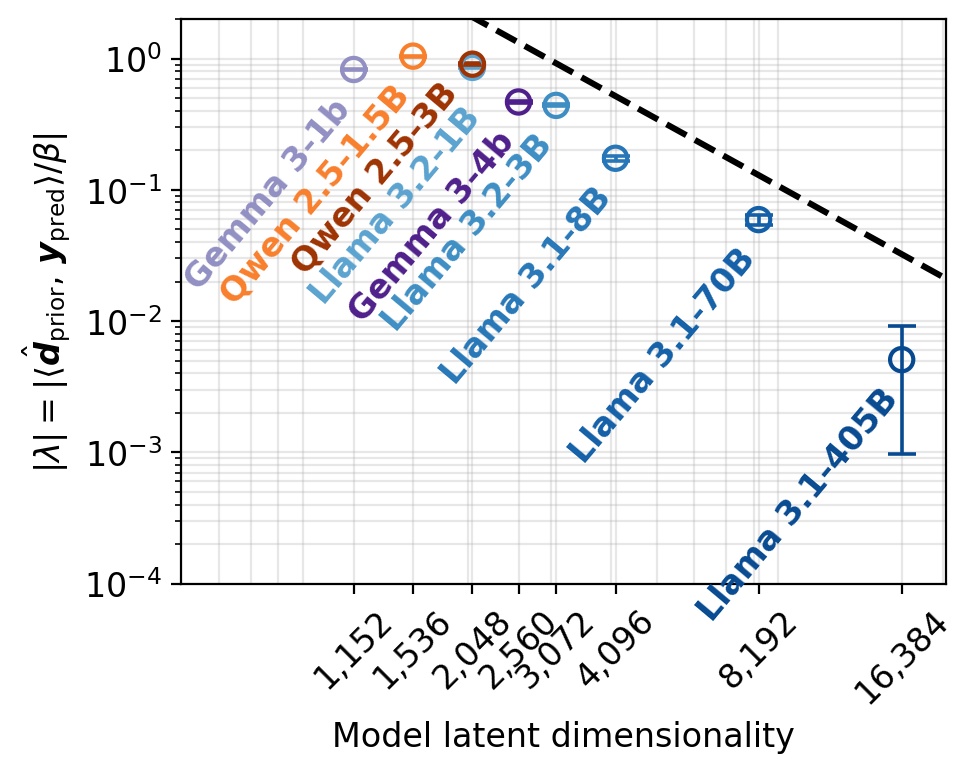

In [9]:
FS = 12
fig, ax = plt.subplots(figsize=(5, 4), dpi=200)
draw_scaling_points(
    ax,
    family_models,
    family_results,
    family_colors,
    marker="o",
)
draw_scaling_points(
    ax,
    pythia_models,
    pythia_results,
    pythia_colors,
    marker="s",
)

family_fits = {}
if fit_family_scaling:
    for family_name, model_names in family_model_groups.items():
        if len(model_names) < 3:
            print(f"{family_name} fit skipped: at least three model sizes are required.")
            continue
        family_fit = fit_power_law(model_names, family_results)
        family_fits[family_name] = family_fit
        fit_x = np.geomspace(family_fit["x_min"], family_fit["x_max"], 300)
        fit_y = family_fit["c"] * fit_x ** family_fit["alpha"]
        fit_color = family_cmaps[family_name.lower()](0.8)
        ax.plot(
            fit_x,
            fit_y,
            color=fit_color,
            linewidth=1.7,
            label=(
                rf"{family_name} fit: $\alpha={family_fit['alpha']:.2f}"
                rf"\pm{family_fit['alpha_se']:.2f}$"
            ),
            zorder=2,
        )
        print(
            f"{family_name} weighted power-law fit: "
            f"c = {family_fit['c']:.6g} ± {family_fit['c_se']:.2g}, "
            f"alpha = {family_fit['alpha']:.6g} ± {family_fit['alpha_se']:.2g}, "
            f"reduced chi^2 = {family_fit['reduced_chi2']:.3g}"
        )

all_results = {**family_results, **pythia_results}
x_values = sorted({result["x"] for result in all_results.values()})
if len(x_values) > 1:
    x_padding_factor = (x_values[-1] / x_values[0]) ** 0.08
else:
    x_padding_factor = 1.2
plot_x_min = x_values[0] / x_padding_factor
plot_x_max = x_values[-1] * x_padding_factor

if show_slope_guide:
    # Extend the power law beyond every x and y boundary. Matplotlib clips it
    # to the axes, so the guide never terminates inside the visible panel.
    if y_axis == "generation_entropy":
        guide_y_bounds = (
            min(result["mean"] for result in all_results.values()),
            max(result["mean"] for result in all_results.values()),
        )
    else:
        guide_y_bounds = y_limits
    guide_x_at_y_bounds = [
        plot_x_min * (y_bound / slope_intercept) ** (1.0 / reference_slope)
        for y_bound in guide_y_bounds
    ]
    guide_x_min = min(plot_x_min, *guide_x_at_y_bounds)
    guide_x_max = max(plot_x_max, *guide_x_at_y_bounds)
    reference_x = np.geomspace(guide_x_min, guide_x_max, 600)
    reference_y = slope_intercept * (
        reference_x / plot_x_min
    ) ** reference_slope
    ax.plot(
        reference_x,
        reference_y,
        "k--",
        linewidth=2.2,
        zorder=2,
    )
    label_x = np.sqrt(plot_x_min * plot_x_max)
    label_y = slope_intercept * (label_x / plot_x_min) ** reference_slope
    # ax.annotate(
    #     rf"slope ${reference_slope:g}$",
    #     xy=(label_x, label_y),
    #     xytext=(0, -16),
    #     textcoords="offset points",
    #     color="black",
    #     fontsize=FS,
    #     ha="center",
    #     va="top",
    # )

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(plot_x_min, plot_x_max)
ax.set_xticks(x_values)
if x_axis == "model_size":
    tick_labels = [f"{value:g}" for value in x_values]
    xlabel = "Model parameters (billions)"
else:
    tick_labels = [f"{int(value):,}" for value in x_values]
    xlabel = "Model latent dimensionality"
ax.set_xticklabels(tick_labels, rotation=45)
ax.tick_params(axis="x", which="minor", bottom=False, labelbottom=False)
ax.tick_params(labelsize=FS)
ax.set_xlabel(xlabel, fontsize=FS)

if y_axis == "generation_entropy":
    ax.set_ylabel(
        "Mean next-token entropy\n"
        r"$H[p_\theta(\cdot\mid x_{<t})]$ (nats)",
        fontsize=FS,
    )
    title_metric = "generation entropy"
else:
    y_label_prefix = (
        "Prior loading strength"
        if y_axis == "absolute_mean_lambda"
        else "Mean absolute prior loading strength"
    )
    ax.set_ylabel(
        # y_label_prefix + "\n"
        r"$|\lambda|=|\langle\hat{\boldsymbol{d}}_{\mathrm{prior}},\,"
        r"\boldsymbol{y}_\mathrm{pred}\rangle/\beta|$",
        fontsize=FS,
    )
    title_metric = "prior loading"
    ax.set_ylim(*y_limits)
    ax.set_xlim(*x_limits)
# ax.set_title(
#     f"Late-context {title_metric}, token positions {interval_start}–{interval_stop - 1}",
#     fontsize=FS,
# )
ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()

coverage_tag = f"{vocab_coverage:g}".replace(".", "p")
coverage_suffix = "" if y_axis == "generation_entropy" else f"_coverage{coverage_tag}"
interval_tag = f"pos{interval_start}-{interval_stop}"
export_path = EXPORT_DIR / (
    f"scaling_law_{y_axis}_vs_{x_axis}{coverage_suffix}_{interval_tag}.pdf"
)
fig.savefig(export_path, bbox_inches="tight")
print(f"fig saved at {export_path}")
plt.show()

### Null hypothesis

This panel copies the main Figure 5 base-model layer and omits all reasoning
models. The blue scaling law is an unweighted log–log OLS fit to the base-model
points. For the matched random-direction control, each model's cached prediction
states $\boldsymbol{y}$ and scale $\beta$ are held fixed while
$\hat{\boldsymbol{d}}_{\mathrm{prior}}$ is replaced by random unit vectors. Each
null point is plotted at its matched base model's latent dimension, with no
interpolation. The same unweighted log–log OLS procedure is applied directly to
the base-model points and their matched null points.


Llama 3.2-1B: d=2048, |lambda|=0.8558 ± 0.0071, null=0.02494 ± 0.0013
Llama 3.2-3B: d=3072, |lambda|=0.4394 ± 0.0055, null=0.01868 ± 0.00097
Llama 3.1-8B: d=4096, |lambda|=0.1738 ± 0.0056, null=0.01277 ± 0.00066
Llama 3.1-70B: d=8192, |lambda|=0.05926 ± 0.0034, null=0.006437 ± 0.00032
Llama 3.1-405B: d=16384, |lambda|=0.00508 ± 0.0027, null=0.0045 ± 0.00024
Gemma 3-1b: d=1152, |lambda|=0.8248 ± 0.0081, null=0.03309 ± 0.0018
Gemma 3-4b: d=2560, |lambda|=0.4665 ± 0.0057, null=0.01758 ± 0.00085
Qwen 2.5-1.5B: d=1536, |lambda|=1.043 ± 0.0078, null=0.02687 ± 0.0014
Qwen 2.5-3B: d=2048, |lambda|=0.9055 ± 0.0072, null=0.0212 ± 0.0013
base fit: alpha = -2.0118 ± 0.2160, c = 2.958e+06
null fit (matched model dimensions): alpha = -0.7901 ± 0.0414, c = 9.146
fig saved under /home/jl3499/LLM_dark_matter/direction_of_ignorance/iclr2027/figures/scaling_matched_random_direction_null


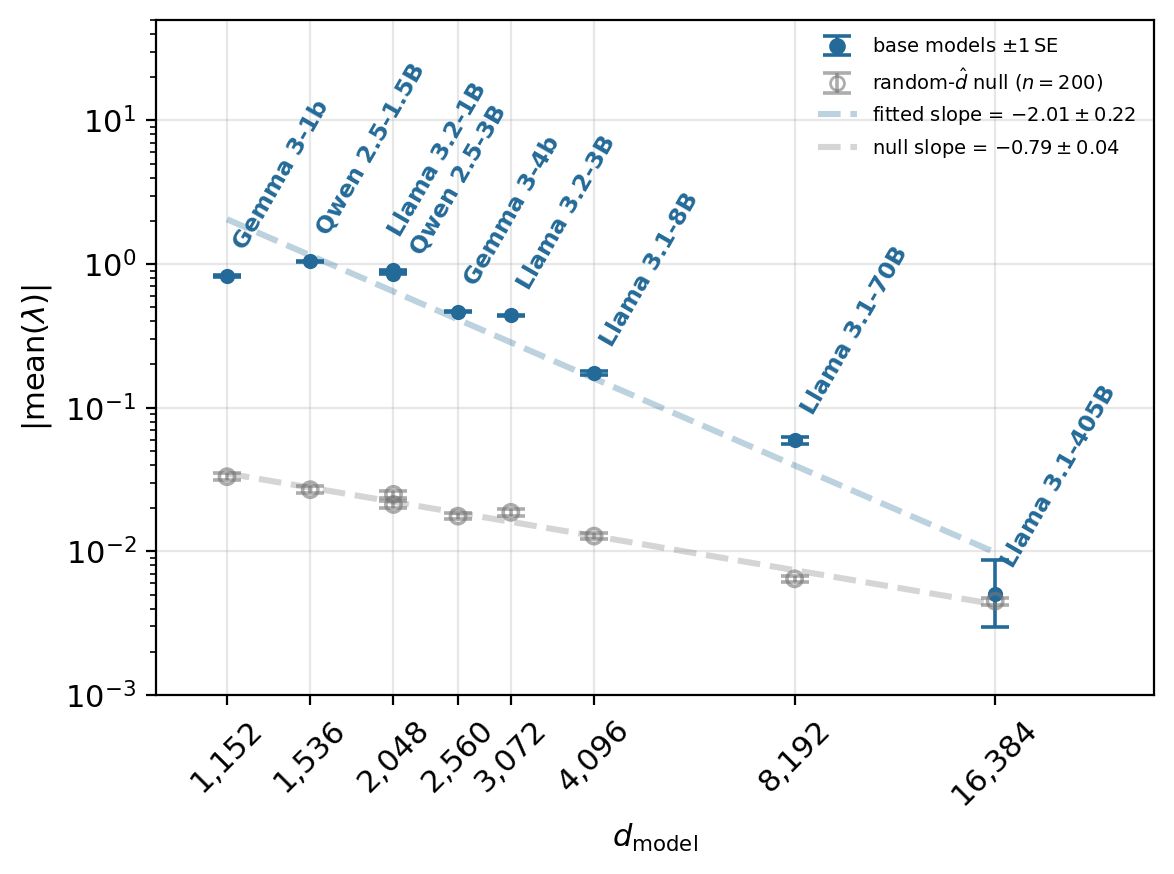

In [10]:
# Matched null: random directions with fixed y and beta (same lambda summary as LLM).
n_random_dirs = 200
rng = np.random.default_rng(0)


def resolve_model_lambda_inputs(model_name):
    """Return (hidden_path, d_hat, beta_star, checkpoint) for one plotted model."""
    if "pythia" in model_name.lower():
        candidates = pythia_cache_candidates(model_name)
        if not candidates:
            # Case-insensitive size tag fallback (e.g. pythia-6.9b vs 6.9B).
            short = model_name.split("/")[-1]
            prefix = f"prior_{short.lower()}_step"
            suffix = f"_N{pythia_num_passages}_T{num_tokens}.npz"
            candidates = sorted(
                (
                    int(re.search(r"_step(\d+)_", path.name).group(1)),
                    path,
                )
                for path in FIG6_CACHE_DIR.glob("prior_pythia-*_step*_N*_T*.npz")
                if path.name.lower().startswith(prefix) and path.name.endswith(suffix)
            )
            candidates = sorted(candidates, reverse=True)
        if not candidates:
            raise FileNotFoundError(f"No Pythia prior caches for {model_name}.")
        for step, cache_path in candidates:
            hidden_path = pythia_hidden_path(model_name, step)
            # Prefer hidden whose tag matches the cache filename's case.
            cache_tag = re.search(r"prior_(pythia-[^_]+)_step", cache_path.name).group(1)
            alt_hidden = FIG6_CACHE_DIR / (
                f"y_{cache_tag}_step{step}_N{pythia_num_passages}_T{num_tokens}_coherent.npy"
            )
            if not hidden_path.exists() and alt_hidden.exists():
                hidden_path = alt_hidden
            if not hidden_path.exists():
                continue
            try:
                d_hat, beta_star = read_prior_fit(cache_path, model_name)
            except RuntimeError:
                continue
            return hidden_path, d_hat, beta_star, step
        raise FileNotFoundError(f"No complete Pythia y/prior pair for {model_name}.")

    cache_path = family_cache_path(model_name)
    hidden_path = family_hidden_path(model_name)
    d_hat, beta_star = read_prior_fit(cache_path, model_name)
    return hidden_path, d_hat, beta_star, None


def matched_random_direction_null(model_name, n_dirs=n_random_dirs):
    """Mean |lambda| under random unit directions, same y/beta/interval as the LLM metric."""
    hidden_path, d_hat, beta_star, checkpoint = resolve_model_lambda_inputs(model_name)
    hidden = np.load(hidden_path, mmap_mode="r")
    interval = np.asarray(
        hidden[:, interval_start:interval_stop, :],
        dtype=np.float32,
    )  # (n_traj, n_pos, d)
    n_traj, n_pos, d_model = interval.shape
    if d_model != d_hat.size:
        raise ValueError(
            f"{model_name}: y dim {d_model} != d_hat dim {d_hat.size}"
        )

    # Flatten tokens, then project onto random unit directions in batches.
    flat = interval.reshape(n_traj * n_pos, d_model)
    null_abs_means = np.empty(n_dirs, dtype=np.float64)
    batch = 32
    for start in range(0, n_dirs, batch):
        stop = min(start + batch, n_dirs)
        gaussians = rng.standard_normal((d_model, stop - start)).astype(np.float32)
        gaussians /= np.linalg.norm(gaussians, axis=0, keepdims=True)
        # (n_traj*n_pos, batch) -> (n_traj, n_pos, batch)
        proj = (flat @ gaussians).reshape(n_traj, n_pos, stop - start) / beta_star
        if y_axis == "mean_absolute_lambda":
            # Match trajectory_interval_lambda: mean |lambda| over tokens, then over traj.
            traj_values = np.abs(proj).mean(axis=1)  # (n_traj, batch)
            null_abs_means[start:stop] = traj_values.mean(axis=0)
        else:
            # absolute_mean_lambda: abs of signed mean over tokens then trajectories.
            traj_values = proj.mean(axis=1)  # (n_traj, batch)
            null_abs_means[start:stop] = np.abs(traj_values.mean(axis=0))

    # Empirical lambda with the true prior direction (same reduction).
    true_values = trajectory_interval_lambda(hidden_path, d_hat, beta_star)
    true_mean, true_se = summarize_trajectory_values(true_values)

    return {
        "x": plotted_x_value(model_name),
        "null_mean": float(null_abs_means.mean()),
        "null_se": float(null_abs_means.std(ddof=1) / np.sqrt(n_dirs)),
        "llm_mean": true_mean,
        "llm_se": true_se,
        "checkpoint": checkpoint,
        "d_model": d_model,
        "beta_star": beta_star,
    }


def fit_loglog_ols(x, y):
    """Unweighted OLS in log–log space: log y = log c + alpha * log x."""
    x = np.asarray(x, dtype=np.float64)
    y = np.asarray(y, dtype=np.float64)
    valid = np.isfinite(x) & np.isfinite(y) & (x > 0) & (y > 0)
    x, y = x[valid], y[valid]
    if x.size < 2:
        raise ValueError("Need at least two positive points.")
    log_x = np.log(x)
    log_y = np.log(y)
    alpha, log_c = np.polyfit(log_x, log_y, 1)
    residual = log_y - (log_c + alpha * log_x)
    dof = max(x.size - 2, 1)
    ss_xx = float(np.sum((log_x - log_x.mean()) ** 2))
    alpha_se = float(np.sqrt(np.sum(residual**2) / dof / ss_xx))
    return {
        "c": float(np.exp(log_c)),
        "alpha": float(alpha),
        "alpha_se": alpha_se,
        "x_min": float(x.min()),
        "x_max": float(x.max()),
    }


# Copy the Figure 5 base-model layer exactly; do not include reasoning models.
base_models = [model for models in families.values() for model, _ in models]
null_rows = {}
for model_name in base_models:
    row = matched_random_direction_null(model_name)
    null_rows[model_name] = row
    print(
        f"{compact_model_label(model_name)}: "
        f"d={row['d_model']}, "
        f"|lambda|={row['llm_mean']:.4g} ± {row['llm_se']:.2g}, "
        f"null={row['null_mean']:.4g} ± {row['null_se']:.2g}"
    )

base_x = np.asarray([null_rows[n]["x"] for n in base_models], dtype=np.float64)
base_y = np.asarray([null_rows[n]["llm_mean"] for n in base_models], dtype=np.float64)
base_se = np.asarray([null_rows[n]["llm_se"] for n in base_models], dtype=np.float64)
null_x = base_x.copy()
null_y = np.asarray([null_rows[n]["null_mean"] for n in base_models], dtype=np.float64)
null_se = np.asarray([null_rows[n]["null_se"] for n in base_models], dtype=np.float64)

# Apply the same unweighted log-log OLS to matched base and random-direction points.
base_fit = fit_loglog_ols(base_x, base_y)
null_fit = fit_loglog_ols(null_x, null_y)
print(
    f"base fit: alpha = {base_fit['alpha']:.4f} ± {base_fit['alpha_se']:.4f}, c = {base_fit['c']:.4g}"
)
print(
    f"null fit (matched model dimensions): "
    f"alpha = {null_fit['alpha']:.4f} ± {null_fit['alpha_se']:.4f}, c = {null_fit['c']:.4g}"
)

fit_x = np.geomspace(
    min(base_fit["x_min"], null_fit["x_min"]),
    max(base_fit["x_max"], null_fit["x_max"]),
    300,
)
null_color = "#777777"
fit_alpha = 0.3


def delta_log_yerr(mean, se):
    """Match Figure 5's one-SE whiskers in log(abs(mean)) space."""
    log_se = se / mean
    lower, upper = mean * np.exp(np.asarray([-1.0, 1.0]) * log_se)
    return np.asarray([[mean - lower], [upper - mean]])


# Same typography as the main Figure 5 cell (fig5_rc, fig5_font, fig5_label_font, fig5_legend_font).
plt.rcParams.update(fig5_rc)
fig, ax = plt.subplots(figsize=(6, 4.5), dpi=200)

# Figure 5 base-model layer: same filled circles, whiskers, labels, and offsets.
for model_name in base_models:
    row = null_rows[model_name]
    x, mean, se = row["x"], row["llm_mean"], row["llm_se"]
    ax.errorbar(x, mean, yerr=delta_log_yerr(mean, se), fmt="none",
                ecolor=fig5_blue, elinewidth=1.3, capsize=5, capthick=1.3, zorder=3)
    ax.scatter(x, mean, s=ms, marker="o", facecolors=fig5_blue,
               edgecolors=fig5_blue, linewidths=0, zorder=4)
    label = (model_name.split("/")[-1]
             .replace("Llama-", "Llama ")
             .replace("gemma-", "Gemma ")
             .replace("Qwen", "Qwen ")
             .replace("-pt", ""))
    offset = ((12, 4) if model_name == "Qwen/Qwen2.5-3B"
              else ((4, 12) if model_name.endswith("Llama-3.2-1B") else (8, 8)))
    ax.annotate(label, (x, mean), xytext=offset, textcoords="offset points",
                fontsize=fig5_label_font, fontweight="bold", color=fig5_blue,
                rotation=60, rotation_mode="anchor", ha="left", va="bottom")

# Base-model scaling fit, using the main figure's blue dashed reference style.
ax.plot(fit_x, base_fit["c"] * fit_x ** base_fit["alpha"],
        color=fig5_blue, ls="--", lw=2.2, alpha=fit_alpha, zorder=2)

# Matched random-direction null at each base model's latent dimension.
for x, mean, se in zip(null_x, null_y, null_se):
    ax.errorbar(x, mean, yerr=delta_log_yerr(mean, se), fmt="none",
                ecolor=null_color, elinewidth=1.3, capsize=5, capthick=1.3,
                alpha=0.6, zorder=3)
ax.scatter(null_x, null_y, s=ms, marker="o", facecolors="none",
           edgecolors=null_color, linewidths=1.3, alpha=0.6, zorder=4)
ax.plot(fit_x, null_fit["c"] * fit_x ** null_fit["alpha"],
        color=null_color, ls="--", lw=2.2, alpha=fit_alpha, zorder=2)

# Copy Figure 5 axes and typography.
xs = sorted({x for models in families.values() for _, x in models})
padding = (xs[-1] / xs[0]) ** 0.08
ax.set(xscale="log", yscale="log",
       xlim=(900, xs[-1] * padding * 1.4), ylim=(0.001, 50))
ax.set_xticks(xs, [f"{x:,}" for x in xs], rotation=45)
ax.tick_params(axis="x", which="minor", bottom=False, labelbottom=False)
ax.tick_params(labelsize=fig5_font)
ax.set_xlabel(r"$d_\text{model}$", fontsize=fig5_font)
ax.set_ylabel(r"$|\mathrm{mean}(\lambda)|$", fontsize=fig5_font)
ax.grid(True, which="major", alpha=0.3)

from matplotlib.lines import Line2D
from matplotlib.container import ErrorbarContainer
from matplotlib.legend_handler import HandlerErrorbar
ax.legend(handles=[
    ax.errorbar([np.nan], [np.nan], yerr=[1.0], fmt="o", color=fig5_blue,
                markersize=5, elinewidth=1.3, capsize=5, capthick=1.3,
                label=r"base models $\pm 1\,\mathrm{SE}$"),
    ax.errorbar([np.nan], [np.nan], yerr=[1.0], fmt="o", color=null_color,
                markerfacecolor="none", markersize=5, elinewidth=1.3,
                capsize=5, capthick=1.3, alpha=0.6,
                label=rf"random-$\hat{{d}}$ null ($n={n_random_dirs}$)"),
    Line2D([], [], color=fig5_blue, linestyle="--", linewidth=2.2, alpha=fit_alpha,
           label=rf"fitted slope = ${base_fit['alpha']:.2f}\pm{base_fit['alpha_se']:.2f}$"),
    Line2D([], [], color=null_color, linestyle="--", linewidth=2.2, alpha=fit_alpha,
           label=rf"null slope = ${null_fit['alpha']:.2f}\pm{null_fit['alpha_se']:.2f}$"),
], loc="upper right", frameon=False, fontsize=fig5_legend_font,
   handler_map={ErrorbarContainer: HandlerErrorbar(yerr_size=0.5)})

fig.tight_layout()
# Export straight into the LaTeX figures directory, like the main Figure 5 cell.
for ext in ("png", "pdf"):
    fig.savefig(figures_dir / f"scaling_matched_random_direction_null.{ext}",
                bbox_inches="tight", dpi=200)
print(f"fig saved under {figures_dir / 'scaling_matched_random_direction_null'}")
plt.show()
